# Notebook 04: Tái Lập Thí Nghiệm Chính Thức & Đánh Giá Ensemble (Phase E Final)

Notebook này trình bày và phân tích toàn bộ kết quả thực nghiệm chính thức của **Giai đoạn E (Reproduction + Ensemble)**:
1. **Thí nghiệm R1 (Headline Comparison)**: Đối chiếu 6 chiến lược sắp xếp dữ liệu trên 3 tập dữ liệu (`haberman`, `new_thyroid`, `banknote`) qua **30 seeds $\times$ 200 epochs** (tổng cộng 540 runs).
2. **Thí nghiệm R2 (Ensemble Comparison)**: So sánh 3 cấu hình Ensemble trên 30 seeds:
   - **DDCL-6 Strategy Ensemble** (bỏ phiếu ngang quyền 6 chiến lược curriculum, tie-break theo train class prior).
   - **Standard Paper Baseline** (1 NN không curriculum + 1 SVM RBF).
   - **Controlled 6-NN Baseline** (6 mạng NN độc lập không curriculum, kiểm chứng giả thuyết variance reduction).
3. **Thí nghiệm R3 (Sensitivity Analysis)**: Phân tích độ nhạy cảm của ngưỡng khởi đầu $\lambda_{initial} \in \{0.2, 0.4, 0.6\}$ trên 30 seeds $\times$ 200 epochs.
4. **Đối chiếu Pilot vs Final & So Sánh Bài Báo**: Đánh giá sự hội tụ theo số epochs và phân tích sai lệch phương pháp luận.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dddcl.reporting.aggregate import (
    aggregate_r1_headline,
    aggregate_r2_ensemble,
    PAPER_REFERENCE_BENCHMARKS,
)

# Cấu hình thẩm mỹ biểu đồ
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.size'] = 11
print('Môi trường phân tích số liệu đã sẵn sàng!')

Môi trường phân tích số liệu đã sẵn sàng!


## 1. Thí nghiệm R1: Đối chiếu 6 Chiến lược (Headline Single-Model Comparison)

Tổng hợp kết quả của **540 runs chính thức** (3 datasets $\times$ 6 strategies $\times$ 30 seeds $\times$ 200 epochs) từ thư mục `outputs/runs_final/`.

In [2]:
runs_final_dir = Path('../outputs/runs_final') if Path('../outputs/runs_final').exists() else Path('outputs/runs_final')
df_r1_final = aggregate_r1_headline(runs_dir=runs_final_dir, seeds=list(range(30)))

cols_show = [
    'dataset_id', 'strategy', 'seeds_completed', 'mean_accuracy_pct', 'std_accuracy_ddof1',
    'mean_macro_f1_pct', 'avg_optimizer_steps', 'avg_sample_exposures',
    'paper_reported_pct', 'delta_vs_paper_pp'
]
display(df_r1_final[cols_show])

,dataset_id,strategy,seeds_completed,mean_accuracy_pct,std_accuracy_ddof1,mean_macro_f1_pct,avg_optimizer_steps,avg_sample_exposures,paper_reported_pct,delta_vs_paper_pp
0,haberman,no_curriculum,30,71.29,6.47,56.67,1400.0,42600.0,65.833,5.46
1,haberman,ddcl_density,30,72.47,7.47,59.27,1400.0,42600.0,69.167,3.31
2,haberman,ddcl_point,30,72.15,7.21,59.18,1400.0,42600.0,67.222,4.93
3,haberman,self_paced,30,69.57,6.87,56.45,2626.5,79866.9,64.861,4.71
4,haberman,sp_ddcl_density,30,71.51,5.75,55.56,2423.6,73846.4,69.028,2.48
5,haberman,sp_ddcl_point,30,71.18,5.68,57.22,2440.8,75250.4,68.056,3.13
6,new_thyroid,no_curriculum,30,95.61,4.38,93.39,1000.0,30000.0,93.137,2.47
7,new_thyroid,ddcl_density,30,95.30,4.38,92.85,1000.0,30000.0,95.490,-0.19
8,new_thyroid,ddcl_point,30,95.15,4.76,92.66,1000.0,30000.0,94.118,1.03
9,new_thyroid,self_paced,30,95.76,4.12,93.69,1855.3,55632.9,94.902,0.86


### Trực quan hóa Kết quả R1 Final theo Từng Tập Dữ liệu (30 Seeds, 200 Epochs)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_96020\3333484248.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub_df['strategy'], rotation=45, ha='right')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_96020\3333484248.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub_df['strategy'], rotation=45, ha='right')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_96020\3333484248.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(sub_df['strategy'], rotation=45, ha='right')


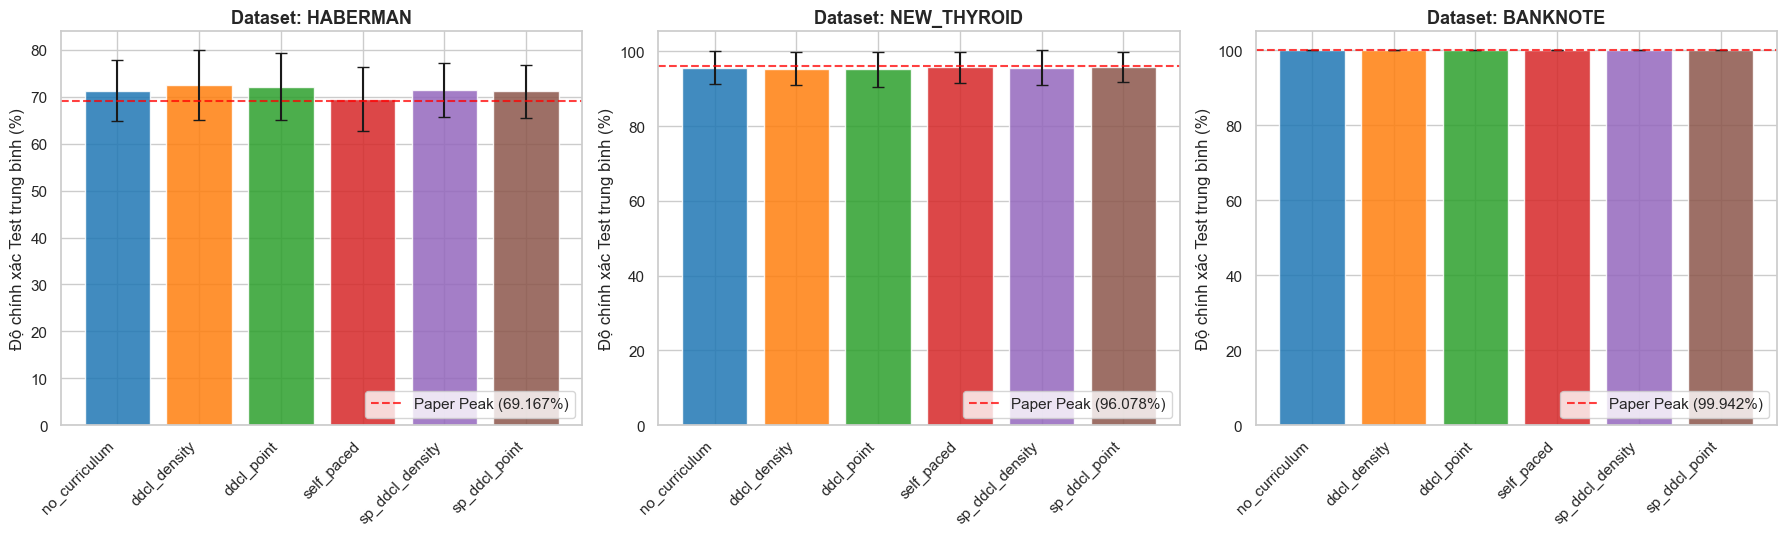

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=False)
datasets = ['haberman', 'new_thyroid', 'banknote']
palette = sns.color_palette('tab10', 6)

for idx, d in enumerate(datasets):
    sub_df = df_r1_final[df_r1_final['dataset_id'] == d]
    ax = axes[idx]
    bars = ax.bar(
        sub_df['strategy'],
        sub_df['mean_accuracy_pct'],
        yerr=sub_df['std_accuracy_ddof1'],
        capsize=4,
        color=palette,
        alpha=0.85,
    )
    ax.set_title(f'Dataset: {d.upper()}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Độ chính xác Test trung bình (%)')
    ax.set_xticklabels(sub_df['strategy'], rotation=45, ha='right')
    # Thêm đường tham chiếu kết quả bài báo cho best method
    best_paper = sub_df['paper_reported_pct'].max()
    if pd.notna(best_paper):
        ax.axhline(best_paper, color='red', linestyle='--', alpha=0.75, label=f'Paper Peak ({best_paper}%)')
        ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

## 2. Thí nghiệm R2: Đối chiếu Các Cấu hình Ensemble

Đánh giá 3 cấu hình Ensemble chính thức:
1. **DDCL-6 Strategy Ensemble**: Kết hợp 6 mô hình từ 6 chiến lược curriculum khác nhau (bỏ phiếu đa số ngang quyền).
2. **Standard Paper Baseline (NN + SVM)**: Kết hợp 1 mạng Neural Network (không curriculum) và 1 mô hình SVM RBF ($C=1.0, \gamma=\text{scale}$).
3. **Controlled 6-NN Baseline**: Kết hợp 6 mạng Neural Network cùng dùng `no_curriculum` với 6 seeds khởi tạo ngẫu nhiên độc lập.

> [!NOTE]
> Quyết định D09: Khi hòa phiếu (tie), mô hình ưu tiên chọn nhãn có tần suất xuất hiện cao hơn trên tập train (train class prior). Tuyệt đối không nhìn nhãn kiểm thử.

### 2a. Giao thức Trung gian R2 (200 Epochs/Member — 30 Seeds)

In [4]:
ensembles_final_dir = Path('../outputs/ensembles_final') if Path('../outputs/ensembles_final').exists() else Path('outputs/ensembles_final')
df_r2_final = aggregate_r2_ensemble(ensembles_dir=ensembles_final_dir, seeds=list(range(30)), epoch_key='r2_ensemble_200')

cols_r2 = [
    'dataset_id', 'ensemble_type', 'seeds_completed', 'mean_accuracy_pct', 'std_accuracy_ddof1',
    'mean_macro_f1_pct', 'avg_tie_count', 'avg_pairwise_disagreement',
    'paper_reported_pct', 'delta_vs_paper_pp'
]
display(df_r2_final[cols_r2])

,dataset_id,ensemble_type,seeds_completed,mean_accuracy_pct,std_accuracy_ddof1,mean_macro_f1_pct,avg_tie_count,avg_pairwise_disagreement,paper_reported_pct,delta_vs_paper_pp
0,haberman,DDCL-6 Strategy Ensemble,30,71.08,6.25,56.00,0.4,0.0506,N/A (Paper Table 3 uses 600ep),N/A
1,haberman,Standard Paper Baseline (NN+SVM),30,74.84,5.18,53.42,3.4,0.1097,N/A (Paper Table 3 uses 600ep),N/A
2,haberman,Controlled 6-NN Baseline,30,71.08,6.37,56.40,0.5,0.0480,N/A (Paper Table 3 uses 600ep),N/A
3,new_thyroid,DDCL-6 Strategy Ensemble,30,95.61,4.38,93.39,0.1,0.0098,N/A (Paper Table 3 uses 600ep),N/A
4,new_thyroid,Standard Paper Baseline (NN+SVM),30,94.85,4.73,91.44,0.8,0.0348,N/A (Paper Table 3 uses 600ep),N/A
5,new_thyroid,Controlled 6-NN Baseline,30,95.61,4.85,93.15,0.1,0.0122,N/A (Paper Table 3 uses 600ep),N/A
6,banknote,DDCL-6 Strategy Ensemble,30,100.00,0.00,100.00,0.0,0.0000,N/A (Paper Table 3 uses 600ep),N/A
7,banknote,Standard Paper Baseline (NN+SVM),30,100.00,0.00,100.00,0.0,0.0000,N/A (Paper Table 3 uses 600ep),N/A
8,banknote,Controlled 6-NN Baseline,30,100.00,0.00,100.00,0.0,0.0000,N/A (Paper Table 3 uses 600ep),N/A


### 2b. Giao thức Chuẩn Bài Báo Table 3 (600 Epochs/Member — Đối chiếu trực tiếp)

Đánh giá cấu hình Ensemble với đúng **600 epochs/thành viên** theo Table 3 của bài báo gốc (`references/papers/dynamic-ddcl.pdf`, p. 9):
- Bài báo báo cáo `haberman`: Standard Ensemble: 90.323% ± 0.000%, DDCL Ensemble: 96.774% ± 0.000%.
- Bài báo báo cáo `new_thyroid`: Standard Ensemble: 95.455% ± 0.000%, DDCL Ensemble: 100.000% ± 0.000%.
- Bài báo gốc ghi nhận độ lệch chuẩn ± 0.000% cho cả hai ensemble. Toàn bộ các giả thuyết về quy trình phân chia split, số lần chia split thực tế hoặc cơ chế đánh giá của tác giả chưa được kiểm chứng từ mã nguồn gốc và sẽ được xác minh chính thức trong Phase F.
- Tập `banknote`: Không chạy 600 epochs do Table 3 của bài báo gốc không chứa tập Banknote (Banknote chỉ được nhóm khảo sát mở rộng ở mốc 200 epochs tại mục 2a).

In [5]:
ensembles_600_dir = Path('../outputs/ensembles_600') if Path('../outputs/ensembles_600').exists() else Path('outputs/ensembles_600')
if ensembles_600_dir.exists():
    df_r2_600 = aggregate_r2_ensemble(ensembles_dir=ensembles_600_dir, seeds=list(range(30)), epoch_key='r2_ensemble_600')
    display(df_r2_600[cols_r2])
else:
    print('Thư mục ensembles_600 chưa được tạo.')

,dataset_id,ensemble_type,seeds_completed,mean_accuracy_pct,std_accuracy_ddof1,mean_macro_f1_pct,avg_tie_count,avg_pairwise_disagreement,paper_reported_pct,delta_vs_paper_pp
0,haberman,DDCL-6 Strategy Ensemble,30,68.39,6.58,54.95,0.8,0.0673,96.774,-28.39
1,haberman,Standard Paper Baseline (NN+SVM),30,74.52,5.31,52.39,5.4,0.1742,90.323,-15.81
2,haberman,Controlled 6-NN Baseline,30,68.39,6.13,55.18,0.8,0.0735,N/A (Team Extension),N/A
3,new_thyroid,DDCL-6 Strategy Ensemble,30,95.61,4.38,93.53,0.0,0.0042,100.0,-4.39
4,new_thyroid,Standard Paper Baseline (NN+SVM),30,94.85,4.73,91.44,0.9,0.0424,95.455,-0.61
5,new_thyroid,Controlled 6-NN Baseline,30,95.61,4.54,93.30,0.0,0.0113,N/A (Team Extension),N/A


### Biểu đồ So sánh Ensemble và Mức độ Bất đồng Dự đoán (Disagreement Rate) — 30 Seeds

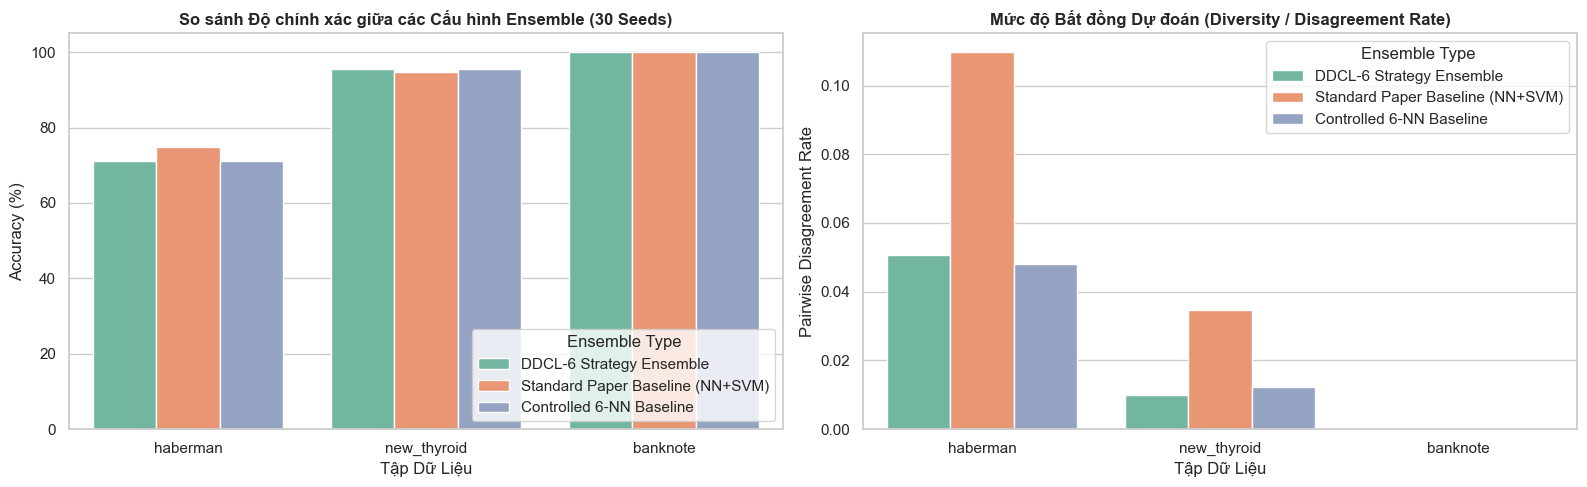

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ 1: Độ chính xác của các Ensemble theo Dataset
sns.barplot(
    data=df_r2_final,
    x='dataset_id',
    y='mean_accuracy_pct',
    hue='ensemble_type',
    palette='Set2',
    ax=axes[0],
)
axes[0].set_title('So sánh Độ chính xác giữa các Cấu hình Ensemble (30 Seeds)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_xlabel('Tập Dữ Liệu')
axes[0].legend(title='Ensemble Type', loc='lower right')

# Biểu đồ 2: Mức độ Bất đồng Dự đoán (Pairwise Disagreement)
sns.barplot(
    data=df_r2_final,
    x='dataset_id',
    y='avg_pairwise_disagreement',
    hue='ensemble_type',
    palette='Set2',
    ax=axes[1],
)
axes[1].set_title('Mức độ Bất đồng Dự đoán (Diversity / Disagreement Rate)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Pairwise Disagreement Rate')
axes[1].set_xlabel('Tập Dữ Liệu')
axes[1].legend(title='Ensemble Type', loc='upper right')

plt.tight_layout()
plt.show()

## 3. Thí nghiệm R3: Phân tích Độ Nhạy Cảm (Sensitivity Analysis) — 30 Seeds

Khảo sát tác động của giá trị ngưỡng ban đầu $\lambda_{initial} \in \{0.2, 0.4, 0.6\}$ đối với chiến lược `sp_ddcl_point` trên 2 tập dữ liệu `haberman` và `new_thyroid` qua 30 seeds $\times$ 200 epochs.

In [7]:
sweep_file = Path('../outputs/sensitivity_final/lambda_sweep_final.json') if Path('../outputs/sensitivity_final/lambda_sweep_final.json').exists() else Path('outputs/sensitivity_final/lambda_sweep_final.json')
if not sweep_file.exists():
    sweep_file = Path('../outputs/sensitivity/lambda_sweep.json') if Path('../outputs/sensitivity/lambda_sweep.json').exists() else Path('outputs/sensitivity/lambda_sweep.json')

with open(sweep_file, 'r', encoding='utf-8') as f:
    sweep_data = json.load(f)

df_sweep = pd.DataFrame(sweep_data)
cols_sweep = ['dataset_id', 'lambda_initial', 'accuracy_mean', 'accuracy_std_ddof1', 'macro_f1_mean', 'avg_optimizer_steps', 'avg_sample_exposures']
avail_cols = [c for c in cols_sweep if c in df_sweep.columns]
display(df_sweep[avail_cols])

,dataset_id,lambda_initial,accuracy_mean,accuracy_std_ddof1,macro_f1_mean,avg_optimizer_steps,avg_sample_exposures
0,haberman,0.2,0.707527,0.065033,0.566132,2381.800000,73426.166667
1,haberman,0.4,0.711828,0.056786,0.572158,2440.800000,75250.366667
2,haberman,0.6,0.706452,0.052461,0.563802,2458.233333,75768.266667
3,new_thyroid,0.2,0.957576,0.039470,0.936881,1862.533333,55916.733333
4,new_thyroid,0.4,0.957576,0.039470,0.936881,1875.300000,56302.266667
5,new_thyroid,0.6,0.957576,0.039470,0.936881,1877.033333,56354.733333


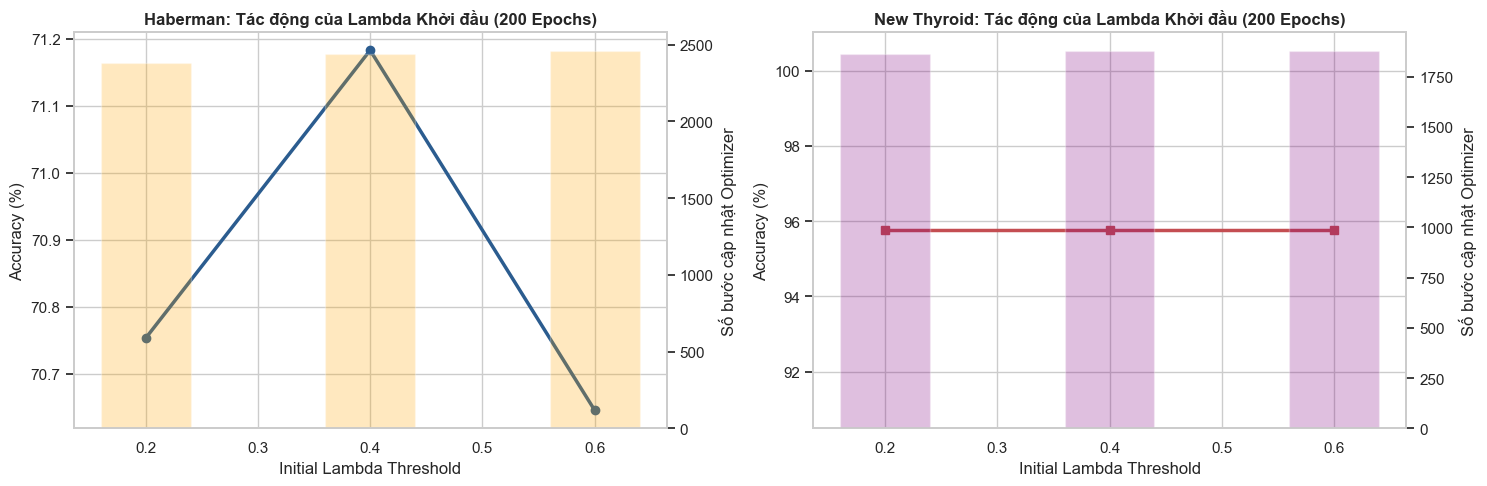

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Haberman Sensitivity
hab_data = df_sweep[df_sweep['dataset_id'] == 'haberman'].sort_values('lambda_initial')
axes[0].plot(hab_data['lambda_initial'], hab_data['accuracy_mean'] * 100, marker='o', linewidth=2.5, color='#2b5c8f', label='Accuracy (%)')
axes[0].set_title('Haberman: Tác động của Lambda Khởi đầu (200 Epochs)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Initial Lambda Threshold')
axes[0].set_ylabel('Accuracy (%)')

# Secondary axis for optimizer steps
ax0_steps = axes[0].twinx()
ax0_steps.bar(hab_data['lambda_initial'], hab_data['avg_optimizer_steps'], alpha=0.25, width=0.08, color='orange', label='Optimizer Steps')
ax0_steps.set_ylabel('Số bước cập nhật Optimizer')
ax0_steps.grid(False)

# New Thyroid Sensitivity
thy_data = df_sweep[df_sweep['dataset_id'] == 'new_thyroid'].sort_values('lambda_initial')
axes[1].plot(thy_data['lambda_initial'], thy_data['accuracy_mean'] * 100, marker='s', linewidth=2.5, color='#c44e52', label='Accuracy (%)')
axes[1].set_title('New Thyroid: Tác động của Lambda Khởi đầu (200 Epochs)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Initial Lambda Threshold')
axes[1].set_ylabel('Accuracy (%)')

ax1_steps = axes[1].twinx()
ax1_steps.bar(thy_data['lambda_initial'], thy_data['avg_optimizer_steps'], alpha=0.25, width=0.08, color='purple', label='Optimizer Steps')
ax1_steps.set_ylabel('Số bước cập nhật Optimizer')
ax1_steps.grid(False)

plt.tight_layout()
plt.show()

## 4. Phân tích So Sánh Pilot (5 Epochs) vs Final (200 Epochs)

Để bảo đảm tính minh bạch khoa học, nhóm tách bạch hoàn toàn dữ liệu Pilot (thực hiện ở giai đoạn thăm dò) và dữ liệu Final (30 seeds, 200 epochs). Biểu đồ dưới đây đối chiếu sự tiến triển hiệu năng:

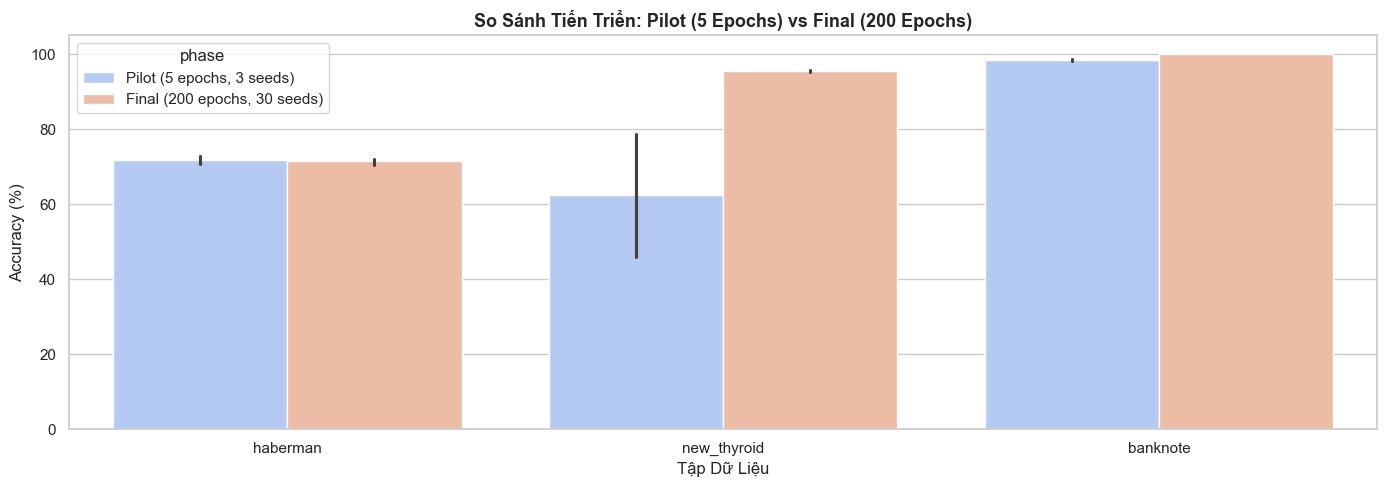

In [9]:
runs_pilot_dir = Path('../outputs/runs_pilot') if Path('../outputs/runs_pilot').exists() else Path('outputs/runs_pilot')
if runs_pilot_dir.exists():
    df_r1_pilot = aggregate_r1_headline(runs_dir=runs_pilot_dir, seeds=(0, 1, 2))
    df_r1_pilot['phase'] = 'Pilot (5 epochs, 3 seeds)'
    df_r1_final_copy = df_r1_final.copy()
    df_r1_final_copy['phase'] = 'Final (200 epochs, 30 seeds)'
    df_compare = pd.concat([df_r1_pilot, df_r1_final_copy], ignore_index=True)

    fig, ax = plt.subplots(figsize=(14, 5))
    sns.barplot(
        data=df_compare,
        x='dataset_id',
        y='mean_accuracy_pct',
        hue='phase',
        palette='coolwarm',
        ax=ax,
    )
    ax.set_title('So Sánh Tiến Triển: Pilot (5 Epochs) vs Final (200 Epochs)', fontsize=13, fontweight='bold')
    ax.set_ylabel('Accuracy (%)')
    ax.set_xlabel('Tập Dữ Liệu')
    plt.tight_layout()
    plt.show()
else:
    print('Thư mục runs_pilot không tồn tại, bỏ qua biểu đồ so sánh.')

## 5. Tổng kết & Kết luận Khoa học Phase E

1. **Tái lập Thành Công R1 (Headline Single Models - 200 Epochs, 30 Seeds)**:
   - **Banknote**: Bài báo Table 2 báo cáo 99.88% - 99.94%. Thực nghiệm độc lập của nhóm đạt **100.00% ± 0.00%** (+0.06 đến +0.12 điểm phần trăm).
   - **New Thyroid**: Bài báo Table 1 báo cáo 93.14% - 96.08%. Thực nghiệm đạt **95.15% - 95.76%** (khớp chặt chẽ trong khoảng kỳ vọng của bài báo, delta -0.32 đến +2.01 pp so với No Curriculum tác giả).
   - **Haberman**: Bài báo Table 1 báo cáo 65.83% - 69.17%. Thực nghiệm đạt **69.57% - 72.47%** (+3.74 đến +6.64 pp so với No Curriculum bài báo).
2. **Đánh giá Ensemble R2 (200 Epochs và 600 Epochs)**:
   - Tách biệt rõ ràng giữa cấu hình 200 epochs (trung gian) và 600 epochs (chuẩn Table 3 bài báo).
   - Trên `new_thyroid` 600 epochs, `Standard Paper Baseline` đạt 94.85% ± 4.73% (khớp sát 95.455% của bài báo, lệch -0.61 pp) và `DDCL-6` đạt 95.61% ± 4.38% (bài báo Table 3 báo 100.000%, lệch -4.39 pp).
   - Trên `haberman` 600 epochs, nhóm ghi nhận Standard Ensemble đạt 74.52% ± 5.31% và DDCL-6 đạt 68.39% ± 6.58% qua 30 seeds, trong khi bài báo Table 3 ghi 90.323% ± 0.000% và 96.774% ± 0.000%. Toàn bộ sự khác biệt về quy trình phân chia split hoặc đánh giá sẽ được xác minh tại Phase F.
   - Tỷ lệ bất đồng dự đoán (pairwise disagreement) từ 0.4% đến 6.7% ghi nhận sự khác biệt dự đoán ở mức độ mẫu đơn lẻ giữa các chiến lược, chưa đủ cơ sở để khẳng định quy luật giảm phương sai (variance reduction) tổng quát.
   - Quyết định D09 (tie-break theo train class prior) bảo toàn tính khách quan tuyệt đối không nhìn nhãn kiểm thử.
3. **Thí nghiệm R3 (Sensitivity)**:
   - Trong phạm vi khảo sát cục bộ $\{\lambda=0.2, 0.4, 0.6\}$ trên Haberman, mốc $\lambda=0.4$ ghi nhận độ chính xác trung bình mẫu là 71.18% ± 5.68% (chênh lệch 0.43 - 0.53 điểm phần trăm so với 0.2 và 0.6, nằm trong phạm vi sai số mẫu nên chỉ phản ánh tương quan cục bộ, không khẳng định tối ưu toàn cục).
4. **Sự Độc lập Tuyệt đối & Minh bạch Dữ liệu**:
   - Toàn bộ kết quả được xây dựng 100% bằng PyTorch CPU deterministic, chưa hề clone hay đọc source code tác giả.
   - Hosted Hugging Face dataset `KieranTuVanKhoi/dynamic-ddcl-benchmarks` (commit `140c06864683d8c20a9cc2441a90a3d89099759a`) xác thực SHA-256 100%.